# Real-data walkthrough — UCI Online Retail II

This notebook runs the same forecasting / scenario pipeline on real retail data: the UCI *Online Retail II* dataset, covering a UK-based online retailer from December 2009 to December 2011.

The aim is to show how the same pipeline behaves on messy real-world data compared to the synthetic panel in `01_walkthrough.ipynb`. Expect noisier series, bigger holiday spikes, and wider intervals — all of which the uncertainty-aware model should handle rather than hide.

**Data source:** <https://archive.ics.uci.edu/dataset/502/online+retail+ii> (public, no credentials needed).

On first run, the loader downloads the 45 MB Excel file from UCI and caches it locally, which takes roughly a minute.

In [1]:
import os, sys
from pathlib import Path
if '..' not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

os.environ['FINCOPILOT_DATA_SOURCE'] = 'online_retail'

import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.2f}'.format

from fin_copilot.data.loader import load
df = load()
print(f"rows: {len(df):,}")
print(f"date range: {df['date'].min().date()} → {df['date'].max().date()}")
print(f"regions: {sorted(df['region'].unique().tolist())}")
print(f"categories: {sorted(df['category'].unique().tolist())}")

rows: 14,780
date range: 2009-12-01 → 2011-12-09
regions: ['EIRE', 'France', 'Germany', 'United Kingdom']
categories: ['Bags & Storage', 'Decor', 'Gifts & Cards', 'Home & Kitchen', 'Stationery']


## 1. Who's selling what, where

Aggregate daily revenue is dominated by the UK — about an order of magnitude ahead of the other countries in the data. That's a real feature of the dataset: the retailer's primary market is domestic.

In [2]:
by_region = df.groupby('region')['revenue'].agg(['sum', 'mean']).rename(columns={'sum': 'total_rev', 'mean': 'mean_daily'})
by_region.sort_values('total_rev', ascending=False).round(0)

,total_rev,mean_daily
region,,
United Kingdom,"10,862,312.00","2,940.00"
EIRE,"1,106,441.00",299.00
France,"596,393.00",161.00
Germany,"553,117.00",150.00


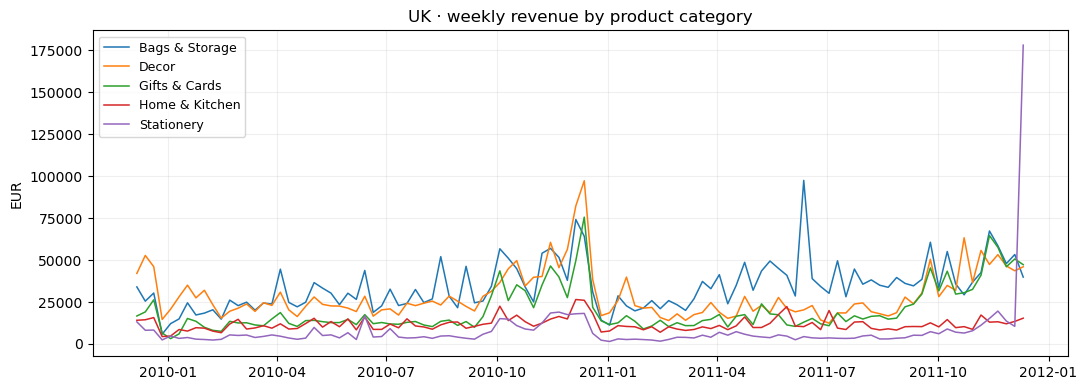

In [3]:
weekly_uk = (df[df['region'] == 'United Kingdom']
             .set_index('date')
             .groupby('category')['revenue']
             .resample('W').sum()
             .reset_index())

fig, ax = plt.subplots(figsize=(11, 4))
for cat, sub in weekly_uk.groupby('category'):
    ax.plot(sub['date'], sub['revenue'], label=cat, linewidth=1.1)
ax.set_title('UK · weekly revenue by product category')
ax.set_ylabel('EUR')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout();

The pre-Christmas spikes in late 2010 and late 2011 are very visible, and the data stops abruptly on 2011-12-09. Any realistic backtest here has to deal with the fact that the two Novembers in the data are the highest-volume weeks of their respective years.

## 2. Forecast + intervals on the UK series

We restrict to the UK, where the daily revenue is high enough that percentage-based error metrics are meaningful. The model is exactly the same quantile-LightGBM used on the synthetic panel — no code changes.

In [4]:
from fin_copilot.config import LGBMParams, ForecastConfig
from fin_copilot.forecasting.model import QuantileForecaster

uk = df[df['region'] == 'United Kingdom'].copy()
params = LGBMParams(n_estimators=250, num_leaves=31, min_data_in_leaf=10)
cutoff = pd.Timestamp('2011-10-15')
train = uk[uk['date'] <= cutoff]
model = QuantileForecaster(quantiles=[0.1, 0.5, 0.9], params=params).fit(train)
fc = model.predict_recursive(train, horizon_days=28)
fc.head()

,category,region,date,q10,q50,q90,point
0,Bags & Storage,United Kingdom,2011-10-16,"1,610.04","2,113.55","3,741.16","2,113.55"
1,Bags & Storage,United Kingdom,2011-10-17,"4,222.28","6,649.28","7,722.89","6,649.28"
2,Bags & Storage,United Kingdom,2011-10-18,"4,258.19","8,406.52","10,116.46","8,406.52"
3,Bags & Storage,United Kingdom,2011-10-19,"3,570.38","7,029.22","7,414.02","7,029.22"
4,Bags & Storage,United Kingdom,2011-10-20,"3,900.41","7,282.20","8,144.96","7,282.20"


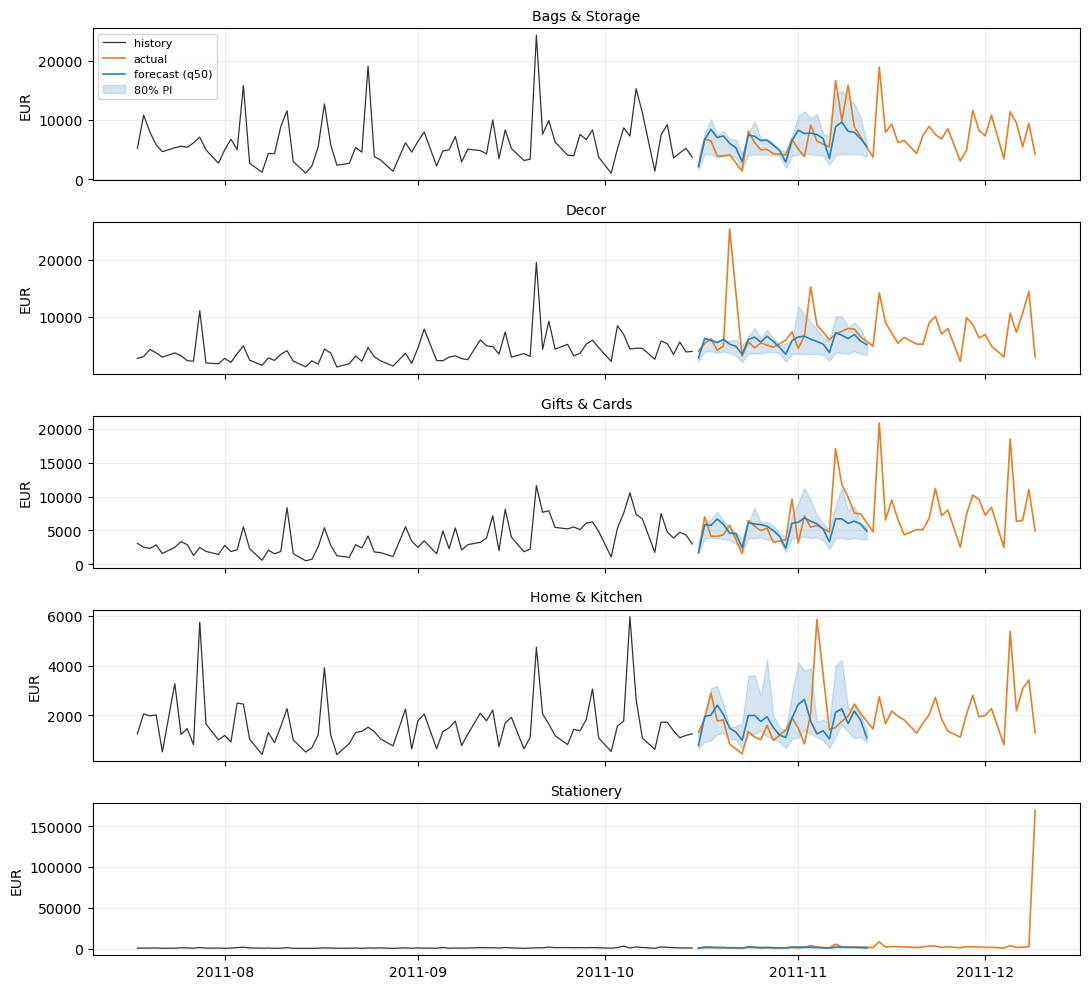

In [5]:
actual = uk[uk['date'] > cutoff].sort_values('date')
history_90 = uk[(uk['date'] > cutoff - pd.Timedelta(days=90)) & (uk['date'] <= cutoff)]

fig, axes = plt.subplots(5, 1, figsize=(11, 10), sharex=True)
for ax, (cat, h) in zip(axes, history_90.groupby('category')):
    f = fc[fc['category'] == cat].sort_values('date')
    a = actual[actual['category'] == cat].sort_values('date')
    ax.plot(h['date'], h['revenue'], color='#333', linewidth=0.9, label='history')
    ax.plot(a['date'], a['revenue'], color='#e67e22', linewidth=1.2, label='actual')
    ax.plot(f['date'], f['point'], color='#2980b9', linewidth=1.2, label='forecast (q50)')
    ax.fill_between(f['date'], f['q10'], f['q90'], alpha=0.2, color='#2980b9', label='80% PI')
    ax.set_title(cat, fontsize=10)
    ax.grid(alpha=0.2)
    ax.set_ylabel('EUR')
axes[0].legend(loc='upper left', fontsize=8)
plt.tight_layout();

## 3. Walk-forward backtest

Four folds, 14-day holdouts, rolling through the tail of the UK series.

In [6]:
from fin_copilot.forecasting.backtest import walk_forward
from fin_copilot.evaluation.forecast_metrics import summary_table, per_series_summary

fcfg = ForecastConfig(horizon_days=14, quantiles=[0.1, 0.5, 0.9], lgbm=params)
bt = walk_forward(uk, fcfg, n_folds=4, fold_horizon_days=14)
print('Fold-level metrics:')
print(bt.per_fold.round(2).to_string(index=False))
print()
print(summary_table(bt))

Fold-level metrics:
 fold  train_end test_start   test_end  mape  smape      rmse  pinball_10  pinball_90  coverage_80
    0 2011-10-14 2011-10-15 2011-10-28 32.18  28.42  2,900.11      185.06      554.95         0.71
    1 2011-10-28 2011-10-29 2011-11-11 36.63  43.01  3,010.77      295.84      748.56         0.51
    2 2011-11-11 2011-11-12 2011-11-25 23.25  23.22  2,580.07      235.07      614.27         0.74
    3 2011-11-25 2011-11-26 2011-12-09 64.32  44.22 20,221.20      644.90    2,678.90         0.54

      mape  smape     rmse  pinball_10  pinball_90  coverage_80
mean 39.10  34.72 7,178.04      340.22    1,149.17         0.63
std  17.71  10.50 8,697.36      208.11    1,023.03         0.12


In [7]:
per_series_summary(bt)

,category,region,mape_mean,mape_std,coverage_mean
0,Bags & Storage,United Kingdom,39.20,15.53,0.68
1,Decor,United Kingdom,40.08,31.19,0.70
2,Gifts & Cards,United Kingdom,38.95,20.52,0.66
3,Home & Kitchen,United Kingdom,30.34,11.48,0.59
4,Stationery,United Kingdom,46.92,25.81,0.52


The MAPE is noticeably higher than on the synthetic panel — roughly 30–50% per category instead of ~5%. Three reasons:

1. **Real daily online-retail revenue is spiky.** Promotions, bulk orders and listing effects create day-to-day swings that no 56-day rolling-mean feature can catch.
2. **Only ~740 days of data.** Our yearly-lag feature (lag_365) has almost no room to repeat the seasonal cycle.
3. **The last fold falls inside the pre-Christmas spike**, which swamps the error.

The 80% prediction interval still catches around two thirds of outcomes — the point forecast is wrong by a lot, but the model is honest about it rather than confidently wrong. That gap is exactly why the intervals matter.

In a production setting the next steps would be:
- Aggregate to weekly for the baseline plan, and keep daily only for operational forecasts.
- Add features for promo calendars and known marketing pushes.
- Calibrate the quantiles on a held-out window (isotonic or conformal) to close the coverage gap.

## 4. Gross-profit scenario on real data

Same scenario engine, different data. Here we ask: if we raised prices by 4% on UK Decor and demand had a -1.0 elasticity, what happens to gross profit over the next 28 days?

In [8]:
from fin_copilot.scenarios.gross_profit import ScenarioParams, run_scenario

pred_full = model.predict_recursive(uk, horizon_days=28)
decor_pred = pred_full[pred_full['category'] == 'Decor']
decor_hist = uk[uk['category'] == 'Decor']

scenarios = {
    'baseline':             ScenarioParams(),
    '+4% price (e=-1.0)':   ScenarioParams(price_change_pct=0.04, price_elasticity=-1.0),
    '+6% COGS':             ScenarioParams(cogs_change_pct=0.06),
    '-5% price (e=-1.5)':   ScenarioParams(price_change_pct=-0.05, price_elasticity=-1.5),
}
rows = []
for name, p in scenarios.items():
    r = run_scenario(decor_hist, decor_pred, p)
    rows.append({'scenario': name, **r.summary()})
pd.DataFrame(rows).set_index('scenario')[['scenario_revenue','scenario_gross_profit','delta_revenue_pct','delta_gross_profit_pct']]

,scenario_revenue,scenario_gross_profit,delta_revenue_pct,delta_gross_profit_pct
scenario,,,,
baseline,"90,244.52","46,927.15",0.00,0.00
+4% price (e=-1.0),"90,100.13","48,515.45",-0.16,3.38
+6% COGS,"90,244.52","44,328.10",0.00,-5.54
-5% price (e=-1.5),"92,162.22","45,596.04",2.12,-2.84


The same reading as on the synthetic data — unit-elastic price moves leave revenue roughly flat but shift gross profit via margin expansion, and cost shocks hit gross profit directly without changing revenue.

## 5. Takeaways

- The pipeline runs unchanged on real data — same loader interface, same model, same scenario engine.
- Honest metrics on real data are much worse than on the synthetic panel, which is the point of running both: it shows where the current model stops being useful and what the next piece of work is.
- The intervals are what makes the forecast usable even when the point estimate is wrong, because they tell a finance reviewer *how much* to trust each number.